In [5]:
from PyMPDATA import Options, ScalarField, VectorField
from PyMPDATA.boundary_conditions import Periodic
import numpy as np
from matplotlib import pyplot as plt
from PyMPDATA import Solver, Stepper

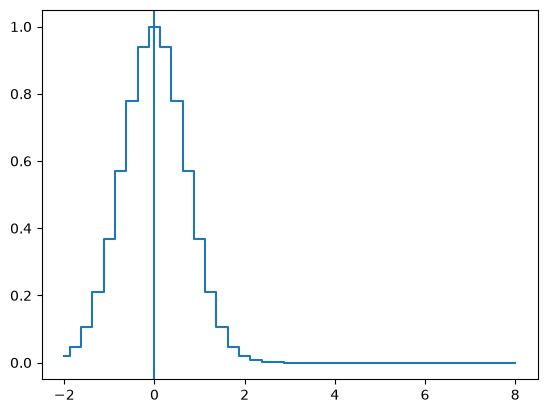

In [6]:
options = Options()

common = {"halo": options.n_halo,
          "boundary_conditions": (Periodic(),)
          }

advectee = ScalarField(**common, data=np.exp(-(x:=np.linspace(-2,8,41))**2))
advector = VectorField(**common, data=(np.full(shape=x.size+1,fill_value=1/4),))

plt.figure()
plt.step(x, advectee.get(), where='mid')
plt.axvline(0)


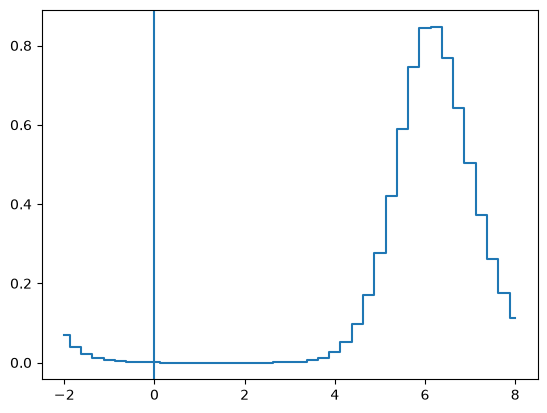

In [7]:

solver = Solver(advector=advector, 
                advectee=advectee,
                stepper=Stepper(n_dims=1, options=options)
                )

solver.advance(n_steps=100) # jak to sie przesuwa po 100 kroksch rownanie: pochdna po czasie pochodna(v psi)=0

plt.figure()
plt.step(x, advectee.get(), where='mid')
plt.axvline(0)
